# Klasifikasi Gambar Sampah dengan CNN dan Transfer Learning

Notebook ini mengikuti alur **CRISP-DM**: Business Understanding, Data Understanding, Data Preparation, Modeling, Evaluation, dan Deployment. Bagian ini mencakup tiga tahap pertama, sampai data siap dipakai untuk training.

Kode yang panjang (dataset, transform, split, dataloader) ada di `src/data.py` supaya notebook tetap ringkas dan fokus ke analisis.

## 0. Setup

Import library, kunci seed 42 untuk semua proses acak, dan cek GPU. Seed yang sama membuat split data dan augmentasi bisa diulang persis.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image

from src.data import (
    BATCH_SIZE, SEED, compute_class_weights, denormalize, find_cross_class_duplicates,
    get_classes, get_transforms, list_images, make_dataloaders, make_splits,
    remove_items, save_splits, set_seed,
)

set_seed(SEED)
DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

# Gaya chart: grid tipis, tanpa garis bingkai atas dan kanan
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
})
BLUE, ORANGE, MUTED = "#2a78d6", "#eb6834", "#52514e"

print("PyTorch:", torch.__version__)
print("CUDA tersedia:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.0+cu132
CUDA tersedia: True
GPU: NVIDIA GeForce RTX 4060


GPU RTX 4060 terdeteksi oleh PyTorch, jadi training nanti bisa berjalan di GPU dengan mixed precision.

## 1. Business Understanding

### Konteks
Di Indonesia, pemilahan sampah sebagian besar masih dilakukan secara manual, baik di rumah tangga, TPS, maupun bank sampah. Prosesnya lambat, melelahkan, dan sering salah karena banyak orang belum tahu cara membedakan jenis material. Padahal industri daur ulang membutuhkan sampah yang sudah terpilah per jenis: kertas, kardus, plastik, kaca, dan logam masing-masing punya jalur daur ulang yang berbeda. Sampah yang tercampur nilainya turun dan sering berakhir di TPA.

### Tujuan
Membangun model yang mengklasifikasikan foto sampah ke **6 kategori**: cardboard (kardus), glass (kaca), metal (logam), paper (kertas), plastic (plastik), dan trash (residu yang tidak bisa didaur ulang). Model ini bisa menjadi dasar untuk:
- sistem pemilahan otomatis (kamera di atas conveyor atau tempat sampah pintar), atau
- aplikasi edukasi, yaitu pengguna memotret sampah lalu aplikasi memberi tahu harus dibuang ke tempat sampah yang mana.

### Pertanyaan yang ingin dijawab
1. Seberapa akurat model bisa mengenali jenis sampah dengan data yang terbatas (sekitar 2.500 gambar)?
2. Seberapa besar keuntungan **transfer learning** dibanding CNN yang dilatih dari nol?
3. Kelas mana yang paling sering tertukar, dan kenapa?
4. Model mana yang paling cocok untuk dipakai di aplikasi nyata, jika mempertimbangkan akurasi, ukuran file, dan kecepatan inferensi?

### Kriteria sukses
| Kriteria | Target |
|---|---|
| Macro F1 di test set | **di atas 0,85** |
| F1 per kelas | tidak ada kelas di bawah 0,70 |
| Ukuran model untuk website demo | di bawah 30 MB (format ONNX) |
| Waktu inferensi di browser | di bawah 1 detik per gambar |

**Kenapa macro F1, bukan cuma akurasi?** Datanya tidak seimbang (kelas trash jauh lebih sedikit dari paper, lihat bagian 2). Akurasi bisa terlihat tinggi walaupun model hampir selalu gagal mengenali kelas kecil, karena kelas kecil hanya menyumbang sedikit ke total. F1 menggabungkan *precision* (dari semua tebakan "trash", berapa yang benar) dan *recall* (dari semua sampah trash, berapa yang berhasil dikenali). **Macro** berarti F1 dihitung per kelas lalu dirata-rata dengan bobot sama, jadi kelas trash dihitung sama penting dengan paper. Target 0,85 dipilih karena penelitian dengan dataset serupa (TrashNet) biasanya mencapai sekitar 0,85 sampai 0,95 dengan transfer learning, sementara CNN dari nol umumnya jauh di bawahnya.

## 2. Data Understanding

Dataset berisi foto sampah yang sudah dikelompokkan per folder kelas di `data/<kelas>/`. Langkah pertama: hitung jumlah gambar per kelas untuk melihat apakah datanya seimbang.

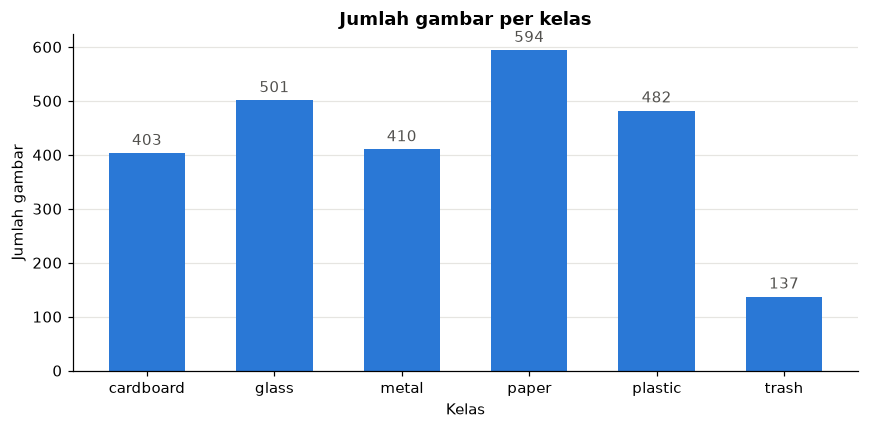

Total gambar: 2527
Kelas terbanyak: paper (594), kelas tersedikit: trash (137)
Rasio imbalance (terbanyak / tersedikit): 4.34


In [2]:
classes = get_classes(DATA_DIR)
all_items = list_images(DATA_DIR)
counts = pd.Series([c for _, c in all_items]).value_counts().reindex(classes)
imbalance_ratio = counts.max() / counts.min()

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(counts.index, counts.values, color=BLUE, width=0.6)
ax.bar_label(bars, padding=3, color=MUTED)
ax.set_title("Jumlah gambar per kelas")
ax.set_xlabel("Kelas")
ax.set_ylabel("Jumlah gambar")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print(f"Total gambar: {counts.sum()}")
print(f"Kelas terbanyak: {counts.idxmax()} ({counts.max()}), kelas tersedikit: {counts.idxmin()} ({counts.min()})")
print(f"Rasio imbalance (terbanyak / tersedikit): {imbalance_ratio:.2f}")

Total ada 2.527 gambar. Paper paling banyak (594) dan trash paling sedikit (137), dengan rasio imbalance sekitar **4,3 : 1**. Lima kelas lain cukup seimbang (400 sampai 600), jadi masalah utamanya ada di kelas trash.

**Dampak ke model:** saat training, model lebih sering melihat contoh paper daripada trash, sehingga cenderung "aman" menebak kelas besar. Akibatnya recall trash bisa rendah walaupun akurasi total terlihat bagus. Ini alasan kita memakai macro F1 sebagai metrik utama dan menambahkan *class weights* di bagian 3.

### Contoh gambar per kelas
Melihat gambar secara langsung membantu memahami seberapa sulit tugasnya dan apakah ada pola yang tidak diinginkan (misalnya latar belakang yang berbeda per kelas).

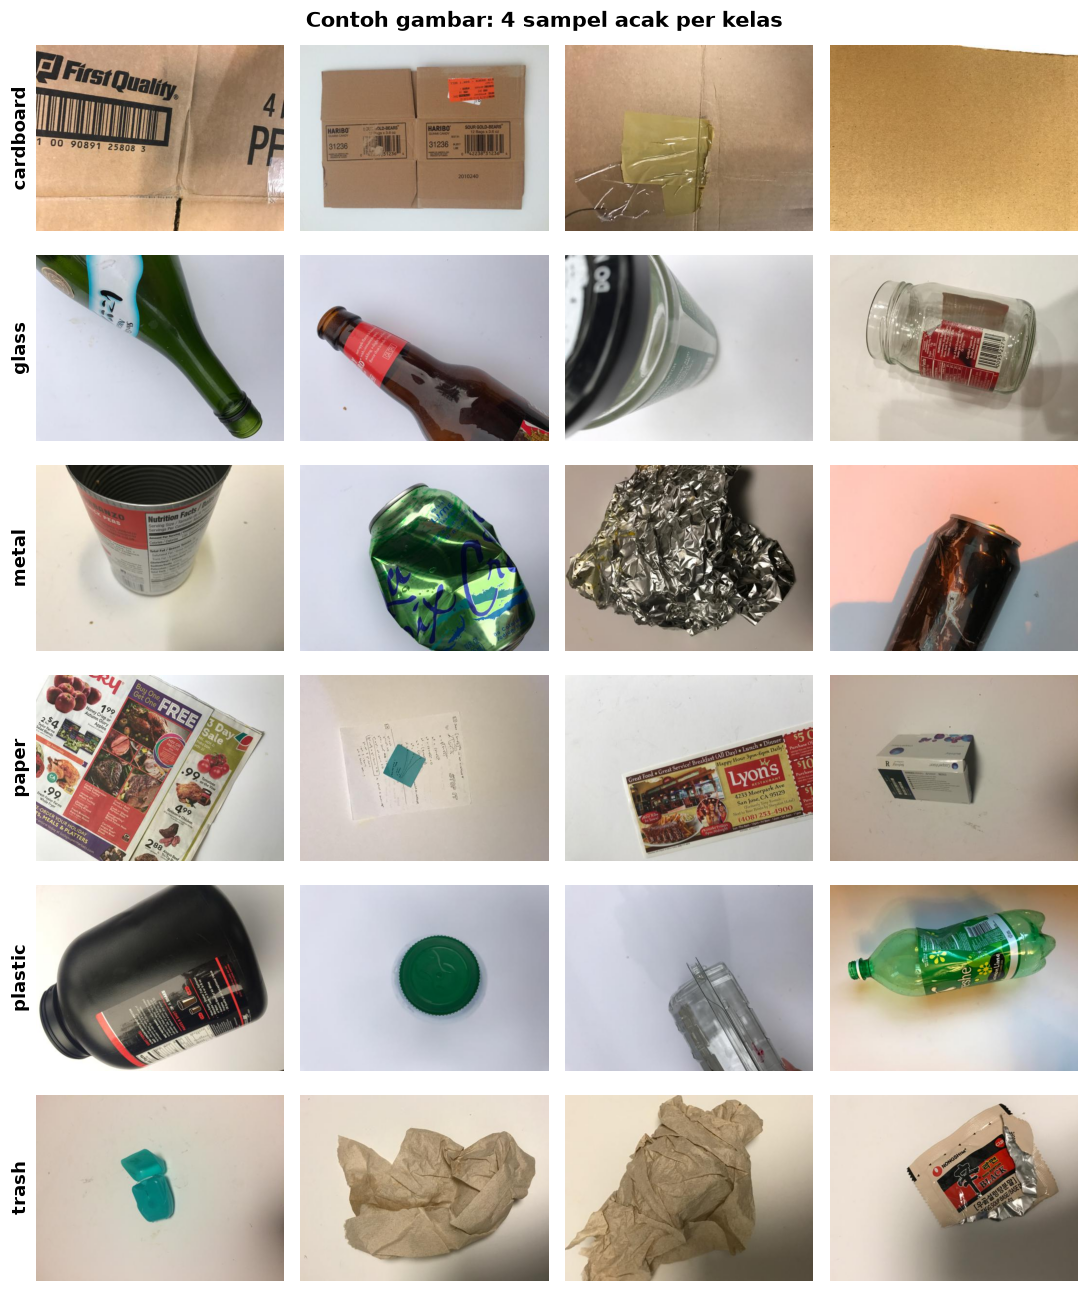

In [3]:
rng = np.random.default_rng(SEED)
n_per_class = 4
fig, axes = plt.subplots(len(classes), n_per_class, figsize=(10, 12))
for r, cls in enumerate(classes):
    cls_items = [p for p, c in all_items if c == cls]
    for k, rel in enumerate(rng.choice(cls_items, n_per_class, replace=False)):
        ax = axes[r, k]
        ax.imshow(Image.open(DATA_DIR / rel))
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(False)
        if k == 0:
            ax.set_ylabel(cls, fontsize=12, fontweight="bold")
fig.suptitle("Contoh gambar: 4 sampel acak per kelas", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

Setiap foto berisi satu objek di atas latar belakang polos (putih atau krem) dengan pencahayaan dalam ruangan. Beberapa kelas mirip secara visual: botol plastik bening mirip botol kaca, dan kertas cetak mengilap mirip kardus tipis, jadi kemungkinan besar pasangan ini yang nanti sering tertukar.

### Resolusi gambar
Resolusi yang beragam memengaruhi cara resize dan crop. Kalau ukurannya sangat bervariasi, resize bisa merusak proporsi objek.

In [4]:
sizes = []
for rel, cls in all_items:
    with Image.open(DATA_DIR / rel) as im:
        sizes.append({"kelas": cls, "lebar": im.width, "tinggi": im.height, "format": im.format, "mode": im.mode})
size_df = pd.DataFrame(sizes)
size_df.groupby(["lebar", "tinggi", "format", "mode"]).size().rename("jumlah gambar").reset_index()

,lebar,tinggi,format,mode,jumlah gambar
0,512,384,JPEG,RGB,2527


Semua 2.527 gambar berukuran sama, **512 x 384 piksel** (rasio 4:3), format JPEG, mode RGB. Jadi preprocessing cukup sederhana: resize sisi pendek lalu crop tengah ke 224 x 224 tanpa distorsi, dan tidak perlu konversi format.

### Rata-rata warna per kelas (cek bias background)
Kalau background atau pencahayaan berbeda per kelas, model bisa "curang": belajar mengenali latar belakang, bukan objeknya. Untuk mengeceknya, kita hitung dua hal per gambar:
- **warna rata-rata seluruh gambar**, yang dipengaruhi objek dan background, dan
- **kecerahan bagian tepi gambar** (bingkai selebar sekitar 6% dari tepi), yang sebagian besar berisi background.

Kalau kecerahan tepi sangat berbeda antar kelas, itu tanda ada bias background.

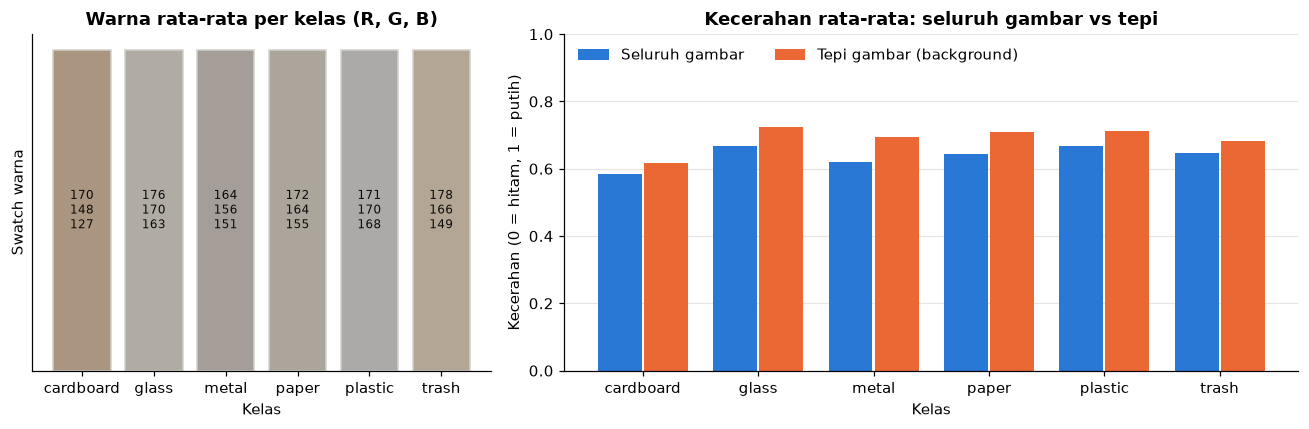

,R,G,B,kecerahan_total,kecerahan_tepi
kelas,,,,,
cardboard,0.667,0.584,0.502,0.584,0.619
glass,0.692,0.669,0.640,0.667,0.724
metal,0.646,0.616,0.596,0.619,0.695
paper,0.675,0.645,0.610,0.643,0.709
plastic,0.671,0.667,0.663,0.667,0.712
trash,0.701,0.651,0.584,0.646,0.684


In [5]:
def color_stats(path, size=(64, 48), border=4):
    arr = np.asarray(Image.open(path).convert("RGB").resize(size), dtype=np.float32) / 255
    edge = np.concatenate([
        arr[:border].reshape(-1, 3), arr[-border:].reshape(-1, 3),
        arr[:, :border].reshape(-1, 3), arr[:, -border:].reshape(-1, 3),
    ])
    r, g, b = arr.reshape(-1, 3).mean(axis=0)
    return r, g, b, arr.mean(), edge.mean()

color_df = pd.DataFrame(
    [(cls, *color_stats(DATA_DIR / rel)) for rel, cls in all_items],
    columns=["kelas", "R", "G", "B", "kecerahan_total", "kecerahan_tepi"],
)
color_mean = color_df.groupby("kelas").mean().reindex(classes)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1, 1.6]})

# Kiri: swatch warna rata-rata per kelas (warna di sini adalah data, bukan palet)
ax1.bar(classes, [1] * len(classes), color=color_mean[["R", "G", "B"]].values, edgecolor="#d0cfca", width=0.8)
for i, cls in enumerate(classes):
    r, g, b = color_mean.loc[cls, ["R", "G", "B"]]
    ax1.text(i, 0.5, f"{int(r*255)}\n{int(g*255)}\n{int(b*255)}", ha="center", va="center", fontsize=8, color="#0b0b0b")
ax1.set_title("Warna rata-rata per kelas (R, G, B)")
ax1.set_xlabel("Kelas")
ax1.set_ylabel("Swatch warna")
ax1.set_yticks([]); ax1.grid(False)

# Kanan: kecerahan total vs kecerahan tepi per kelas
x = np.arange(len(classes))
w = 0.38
b1 = ax2.bar(x - w / 2 - 0.01, color_mean["kecerahan_total"], w, color=BLUE, label="Seluruh gambar")
b2 = ax2.bar(x + w / 2 + 0.01, color_mean["kecerahan_tepi"], w, color=ORANGE, label="Tepi gambar (background)")
ax2.set_xticks(x, classes)
ax2.set_ylim(0, 1)
ax2.set_title("Kecerahan rata-rata: seluruh gambar vs tepi")
ax2.set_xlabel("Kelas")
ax2.set_ylabel("Kecerahan (0 = hitam, 1 = putih)")
ax2.grid(axis="x", visible=False)
ax2.legend(loc="upper left", ncol=2, frameon=False)
plt.tight_layout()
plt.show()

color_mean.round(3)

Kecerahan tepi lima kelas mirip, sekitar 0,68 sampai 0,72, jadi latar belakangnya secara umum seragam dan tidak ada kelas yang difoto di latar yang jelas berbeda. Pengecualiannya cardboard: tepinya lebih gelap (0,62) dan warnanya lebih kekuningan (B rata-rata paling rendah) karena kardus sering memenuhi seluruh frame sampai ke tepi. Perbedaan ini berasal dari objeknya sendiri, bukan dari background, tetapi tetap berarti model bisa memakai warna cokelat sebagai petunjuk kuat untuk cardboard dan perlu dicek lagi di tahap evaluasi (Grad-CAM).

### Keterbatasan dataset
Dari eksplorasi di atas, ada beberapa keterbatasan yang perlu dicatat karena memengaruhi seberapa baik model bekerja di dunia nyata:

1. **Background seragam dan pencahayaan dalam ruangan.** Semua foto diambil di atas latar putih atau krem. Di dunia nyata (tempat sampah, TPS, conveyor), latarnya ramai dan kotor, jadi akurasi di lapangan kemungkinan lebih rendah dari akurasi di test set.
2. **Satu objek per gambar, bersih, dan utuh.** Sampah asli sering bertumpuk, basah, kotor, atau hancur.
3. **Ukuran data kecil.** Sekitar 2.500 gambar, dan kelas trash hanya 137 gambar. CNN dari nol akan sulit belajar, sehingga transfer learning dan augmentasi menjadi penting.
4. **Kelas trash sangat beragam.** Isinya campuran bungkus snack, sedotan, plastik kemasan, dan lain-lain, sehingga polanya sulit dipelajari dari sedikit contoh.
5. **Produk bukan khas Indonesia.** Kemasan dan merek berasal dari luar negeri (dataset TrashNet dari Amerika Serikat), jadi bisa ada perbedaan dengan sampah lokal.
6. **Ada gambar duplikat dengan label berbeda** (dibahas di bagian 3).

## 3. Data Preparation

Semua fungsi di bagian ini diimplementasikan di `src/data.py`, supaya bisa dipakai ulang saat training dan evaluasi.

### 3.1 Membersihkan duplikat antar kelas
Kita cari file yang isinya identik (hash MD5 sama) tetapi berada di dua folder kelas berbeda. Gambar seperti ini membingungkan model karena satu foto punya dua label, dan bisa bocor ke train dan test sekaligus.

In [6]:
duplicates = find_cross_class_duplicates(DATA_DIR, all_items)
pd.DataFrame(
    [{"file A": g[0][0], "file B": g[1][0]} for g in duplicates]
)

,file A,file B
0,glass/glass115.jpg,metal/metal91.jpg
1,glass/glass176.jpg,plastic/plastic152.jpg
2,glass/glass389.jpg,plastic/plastic332.jpg


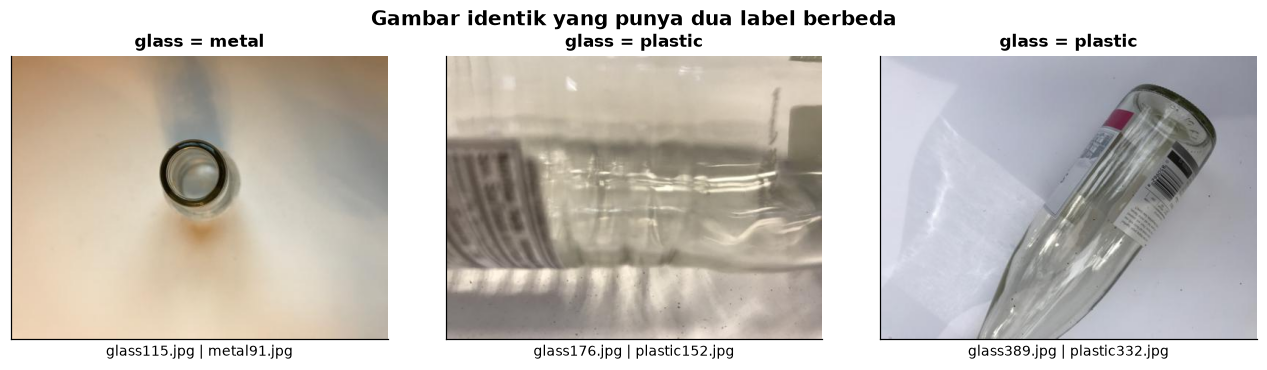

Dibuang: 6 file, sisa: 2521 gambar


In [7]:
fig, axes = plt.subplots(1, len(duplicates), figsize=(12, 3.2))
for ax, group in zip(axes, duplicates):
    ax.imshow(Image.open(DATA_DIR / group[0][0]))
    ax.set_title(" = ".join(c for _, c in group), fontsize=11)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_xlabel(" | ".join(Path(p).name for p, _ in group), fontsize=9)
fig.suptitle("Gambar identik yang punya dua label berbeda", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

to_remove = [rel for group in duplicates for rel, _ in group]
items = remove_items(all_items, to_remove)
print(f"Dibuang: {len(to_remove)} file, sisa: {len(items)} gambar")

Ada 3 pasang gambar identik dengan label bertentangan, misalnya leher botol kaca yang juga ada di folder metal. Karena label yang benar tidak bisa dipastikan, kedua salinan dari tiap pasang dibuang (6 file, hanya 0,2% data), sehingga tersisa 2.521 gambar.

### 3.2 Split stratified train / validation / test (70 / 15 / 15)
- **Train** dipakai untuk melatih model.
- **Validation** dipakai untuk memilih model dan hyperparameter (early stopping, learning rate).
- **Test** hanya dipakai **sekali** di akhir, supaya hasilnya jujur dan tidak "tercemar" oleh keputusan kita selama eksperimen.

Split dibuat **stratified**, artinya proporsi tiap kelas sama di ketiga split. Tanpa ini, bisa saja kelas trash yang hanya 137 gambar kebetulan sangat sedikit di test set. Daftar file per split disimpan ke `outputs/splits.json` supaya semua eksperimen memakai split yang sama persis.

In [8]:
splits = make_splits(items, val_size=0.15, test_size=0.15, seed=SEED)
save_splits(splits, classes, OUTPUT_DIR / "splits.json", extra={"removed_duplicates": to_remove})

split_table = pd.DataFrame(
    {name: pd.Series([c for _, c in s]).value_counts() for name, s in splits.items()}
).reindex(classes)
split_table.loc["TOTAL"] = split_table.sum()
split_pct = (split_table.div(split_table.sum(axis=1), axis=0) * 100).round(1).add_suffix(" (%)")
pd.concat([split_table, split_pct], axis=1)

,train,val,test,train (%),val (%),test (%)
cardboard,282,60,61,70.0,14.9,15.1
glass,348,75,75,69.9,15.1,15.1
metal,286,61,62,69.9,14.9,15.2
paper,416,89,89,70.0,15.0,15.0
plastic,336,72,72,70.0,15.0,15.0
trash,96,21,20,70.1,15.3,14.6
TOTAL,1764,378,379,70.0,15.0,15.0


Hasilnya 1.764 gambar train, 378 validation, dan 379 test. Setiap kelas terbagi mendekati 70/15/15, termasuk trash (96/21/20), sehingga semua split punya komposisi kelas yang sama.

### 3.3 Transformasi dan augmentasi
Model pretrained di ImageNet menerima gambar 224 x 224 yang dinormalisasi dengan mean dan std ImageNet, jadi kita pakai format yang sama.

**Transform train (dengan augmentasi):**
- `RandomResizedCrop(224, scale 0,7 sampai 1,0)`: memotong bagian acak lalu resize, seolah foto diambil dari jarak dan posisi berbeda.
- `RandomHorizontalFlip`: sampah tetap sampah walaupun dicerminkan.
- `RandomRotation(15 derajat)`: rotasi kecil, meniru kamera yang agak miring.
- `ColorJitter` ringan: variasi kecerahan, kontras, dan saturasi, meniru pencahayaan yang berbeda. Hue hanya digeser sedikit karena warna adalah ciri penting (kardus cokelat, kaca hijau).

**Transform val/test (tanpa augmentasi):** resize sisi pendek ke 256, center crop 224, lalu normalisasi. Evaluasi harus deterministik supaya hasilnya bisa dibandingkan.

**Kenapa augmentasi penting untuk dataset kecil?** Dengan hanya sekitar 1.700 gambar train, model mudah *menghafal* gambar training (overfitting): akurasi train tinggi tetapi gagal di gambar baru. Augmentasi membuat setiap epoch melihat versi gambar yang sedikit berbeda, sehingga model dipaksa belajar ciri yang benar-benar penting (bentuk, tekstur, material), bukan posisi atau pencahayaan tertentu.

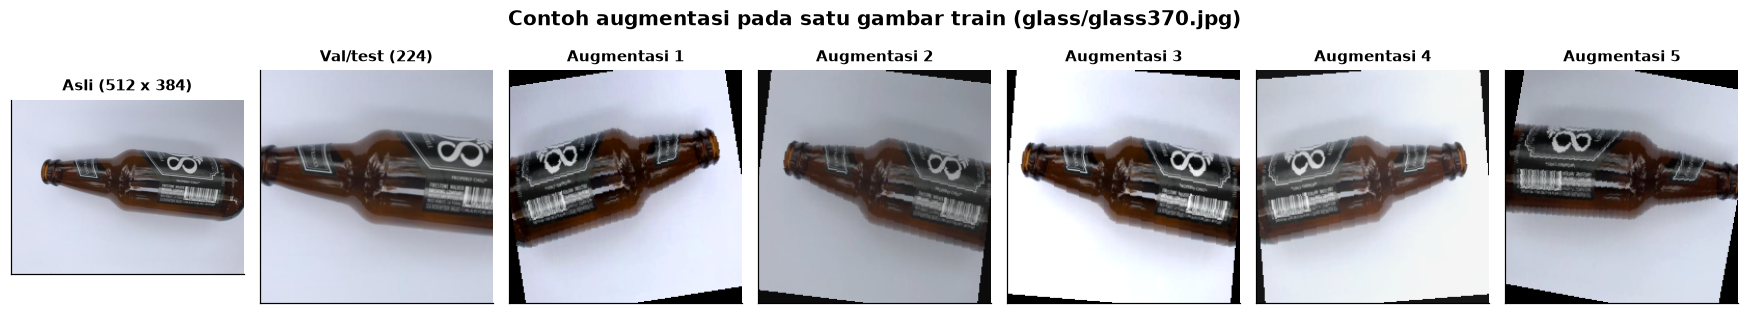

In [9]:
train_tf = get_transforms(train=True)
eval_tf = get_transforms(train=False)
set_seed(SEED)

# Botol kaca dengan objek yang jelas, dipilih dari data train
sample_rel = "glass/glass370.jpg"
assert sample_rel in {rel for rel, _ in splits["train"]}
original = Image.open(DATA_DIR / sample_rel).convert("RGB")
n_aug = 5
fig, axes = plt.subplots(1, n_aug + 2, figsize=(16, 3))
panels = [(original, "Asli (512 x 384)"), (denormalize(eval_tf(original)), "Val/test (224)")]
panels += [(denormalize(train_tf(original)), f"Augmentasi {i+1}") for i in range(n_aug)]
for ax, (img, title) in zip(axes, panels):
    ax.imshow(img if isinstance(img, Image.Image) else img.permute(1, 2, 0).numpy())
    ax.set_title(title, fontsize=10)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle(f"Contoh augmentasi pada satu gambar train ({sample_rel})", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

Dari satu foto yang sama, augmentasi menghasilkan variasi posisi, skala, sudut, dan pencahayaan, tetapi objeknya tetap jelas botol kaca, jadi label tidak berubah. Sudut hitam kecil muncul akibat rotasi, dan karena posisinya acak di setiap epoch, model tidak menjadikannya ciri kelas tertentu.

### 3.4 Class weights untuk menangani imbalance
Saat training, loss (kesalahan) dari setiap gambar dikalikan dengan bobot kelasnya. Rumus yang dipakai adalah bobot "balanced":

$$w_c = \frac{N_{total}}{K \times N_c}$$

dengan $N_{total}$ = jumlah gambar train, $K$ = jumlah kelas (6), dan $N_c$ = jumlah gambar kelas $c$. Kelas yang jarang dapat bobot besar, sehingga satu kesalahan pada gambar trash "dihukum" lebih berat daripada satu kesalahan pada paper. Secara total, setiap kelas jadi punya pengaruh yang kira-kira sama ke loss. Bobot dihitung **hanya dari data train** supaya informasi dari val/test tidak bocor.

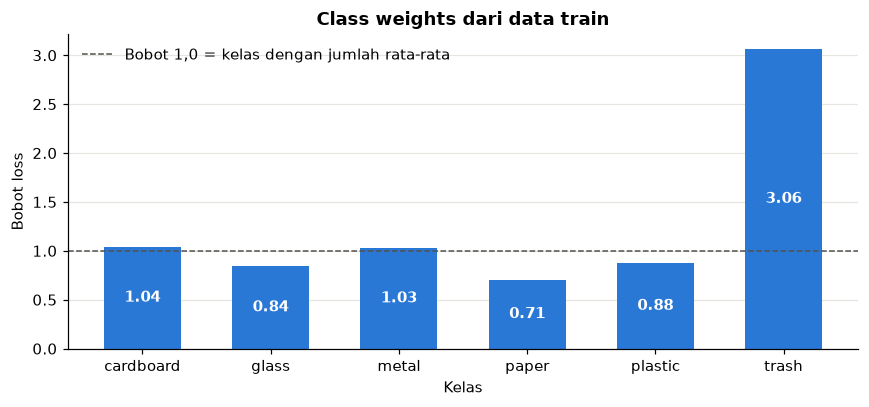

,jumlah train,class weight
cardboard,282,1.043
glass,348,0.845
metal,286,1.028
paper,416,0.707
plastic,336,0.875
trash,96,3.062


In [10]:
class_weights = compute_class_weights(splits["train"], classes)
train_counts = split_table.loc[classes, "train"]
weights_df = pd.DataFrame({"jumlah train": train_counts, "class weight": class_weights.numpy().round(3)})

fig, ax = plt.subplots(figsize=(8, 3.8))
bars = ax.bar(classes, class_weights.numpy(), color=BLUE, width=0.6)
ax.bar_label(bars, fmt="%.2f", label_type="center", color="white", fontweight="bold")
ax.axhline(1.0, color=MUTED, linewidth=1, linestyle="--", label="Bobot 1,0 = kelas dengan jumlah rata-rata")
ax.legend(loc="upper left", frameon=False)
ax.set_title("Class weights dari data train")
ax.set_xlabel("Kelas")
ax.set_ylabel("Bobot loss")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

weights_df

Trash mendapat bobot sekitar 3,06, artinya satu kesalahan pada gambar trash dihitung kira-kira 3 kali lebih berat dari rata-rata. Paper, kelas terbesar, mendapat bobot terkecil (0,71). Bobot ini nanti dipasang di `CrossEntropyLoss(weight=class_weights)` saat training.

### 3.5 DataLoader
DataLoader mengambil gambar per batch, menerapkan transform, lalu mengirimnya ke model. Batch size 32 dengan gambar 224 x 224 aman untuk VRAM 8 GB, bahkan untuk model yang cukup besar. `num_workers=0` dipakai karena DataLoader multi-proses sering bermasalah di notebook Windows. Hanya data train yang diacak (shuffle), dengan generator ber-seed supaya urutannya bisa diulang.

In [11]:
loaders = make_dataloaders(DATA_DIR, splits, classes, batch_size=BATCH_SIZE, num_workers=0)
images, labels = next(iter(loaders["train"]))

pd.DataFrame({
    name: {"jumlah gambar": len(dl.dataset), "jumlah batch": len(dl), "shuffle": name == "train"}
    for name, dl in loaders.items()
}).T

,jumlah gambar,jumlah batch,shuffle
train,1764,56,True
val,378,12,False
test,379,12,False


In [12]:
print("Bentuk batch gambar:", tuple(images.shape), "| tipe:", images.dtype)
print("Bentuk batch label :", tuple(labels.shape))
print(f"Rentang nilai piksel setelah normalisasi: {images.min():.2f} sampai {images.max():.2f}")
print("Label di batch pertama:", pd.Series([classes[i] for i in labels.tolist()]).value_counts().to_dict())

Bentuk batch gambar: (32, 3, 224, 224) | tipe: torch.float32
Bentuk batch label : (32,)
Rentang nilai piksel setelah normalisasi: -2.12 sampai 2.64
Label di batch pertama: {'paper': 8, 'plastic': 8, 'glass': 7, 'metal': 5, 'cardboard': 4}


Satu batch berisi 32 gambar berukuran 3 x 224 x 224 dengan label bilangan bulat 0 sampai 5, sesuai format input CNN di PyTorch. Nilai piksel sudah dinormalisasi (sekitar -2 sampai 2,6), dan batch pertama berisi campuran kelas karena data train diacak.

**Ringkasan Data Preparation:** data sudah bersih dari duplikat, terbagi stratified 70/15/15 (disimpan di `outputs/splits.json`), punya augmentasi untuk train, class weights untuk menangani imbalance, dan DataLoader yang siap dipakai. Tahap berikutnya adalah **Modeling**.